# Mid-term 2: Phân tích Bank Marketing

Mục tiêu của bài là so sánh tỷ lệ đăng ký tiền gửi giữa các nhóm khách hàng, từ đó đề xuất hướng thử nghiệm cho chiến dịch marketing. Dữ liệu sử dụng là `bank.csv`, thuộc [Bank Marketing Dataset trên Kaggle](https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset).

Đặt `bank.csv` cùng thư mục với notebook khi chạy trên Jupyter. Nếu file nằm ở thư mục khác, nhập đường dẫn khi được hỏi. Trên Colab, notebook kết nối Google Drive để đọc file; nếu chưa có file, chọn tải lên trực tiếp.

In [1]:
# Kết nối Drive hoặc chọn file dữ liệu
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from IPython.display import display

data_path = Path('bank.csv')
if 'google.colab' in sys.modules:
    from google.colab import drive, files
    drive_path = Path('/content/drive/MyDrive/bank.csv')
    try:
        drive.mount('/content/drive')
    except Exception as exc:
        print(f'Không kết nối được Drive: {exc}')
    if drive_path.is_file():
        data_path = drive_path
    elif not data_path.is_file():
        print('Chọn file bank.csv để tải lên Colab.')
        uploaded = files.upload()
        if 'bank.csv' not in uploaded:
            raise FileNotFoundError('Hãy tải lên đúng file bank.csv.')
elif not data_path.is_file():
    data_path = Path(input('Nhập đường dẫn tới bank.csv: ').strip()).expanduser()

if not data_path.is_file():
    raise FileNotFoundError(f'Không tìm thấy file dữ liệu: {data_path}')
df = pd.read_csv(data_path)
pd.set_option('display.max_columns', None)
print('Đọc dữ liệu từ:', data_path)
print('Kích thước:', df.shape)
display(df.head())

Đọc dữ liệu từ: bank.csv
Kích thước: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


## 1. Thu thập và đánh giá dữ liệu

Dữ liệu gồm một file CSV với 11.162 dòng và 17 cột. Mỗi dòng chứa thông tin khách hàng, thông tin liên hệ và kết quả đăng ký tiền gửi. Các cột được chia thành các nhóm:

- Thông tin cá nhân: `age`, `job`, `marital`, `education`.
- Thông tin tài chính: `balance`, `housing`, `loan`, `default`.
- Thông tin liên hệ và lịch sử chiến dịch: `contact`, `day`, `month`, `duration`, `campaign`, `pdays`, `previous`, `poutcome`.
- Kết quả đăng ký: `deposit`, gồm `yes` và `no`.

Bài chỉ sử dụng một file nên không có bước nối bảng. Biến `duration` là thời lượng cuộc gọi, chỉ biết sau khi gọi nên không dùng để lựa chọn khách hàng trước cuộc gọi.

In [2]:
# Kiểm tra cấu trúc, giá trị thiếu và các nhãn chưa biết
print('Kiểu dữ liệu và số giá trị không thiếu:')
df.info()
quality = pd.DataFrame({'Kiểu': df.dtypes.astype(str), 'Thiếu': df.isna().sum(), 'Thiếu (%)': df.isna().mean() * 100,
                        'Số giá trị khác nhau': df.nunique()})
display(quality)
print('Số dòng trùng hoàn toàn:', df.duplicated().sum())
print('Số giá trị unknown theo cột:')
unknown_counts = (df == 'unknown').sum()
display(unknown_counts[unknown_counts > 0])
display(df.describe().T)

Kiểu dữ liệu và số giá trị không thiếu:
<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


,Kiểu,Thiếu,Thiếu (%),Số giá trị khác nhau
age,int64,0,0.0,76
job,str,0,0.0,12
marital,str,0,0.0,3
education,str,0,0.0,4
default,str,0,0.0,2
balance,int64,0,0.0,3805
housing,str,0,0.0,2
loan,str,0,0.0,2
contact,str,0,0.0,3
day,int64,0,0.0,31


Số dòng trùng hoàn toàn: 0
Số giá trị unknown theo cột:


job            70
education     497
contact      2346
poutcome     8326
dtype: int64

,count,mean,std,min,25%,50%,75%,max
age,11162.0,41.231948,11.913369,18.0,32.0,39.0,49.00,95.0
balance,11162.0,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.00,81204.0
day,11162.0,15.658036,8.420740,1.0,8.0,15.0,22.00,31.0
duration,11162.0,371.993818,347.128386,2.0,138.0,255.0,496.00,3881.0
campaign,11162.0,2.508421,2.722077,1.0,1.0,2.0,3.00,63.0
pdays,11162.0,51.330407,108.758282,-1.0,-1.0,-1.0,20.75,854.0
previous,11162.0,0.832557,2.292007,0.0,0.0,0.0,1.00,58.0


## 2. Làm sạch và kiểm tra bất thường

Giá trị `unknown` được giữ thành một nhóm riêng vì chưa có cơ sở để điền thông tin thay thế. Với `pdays`, giá trị -1 có nghĩa là khách hàng chưa được liên hệ trong chiến dịch trước. Bài kiểm tra và loại dòng trùng hoàn toàn nếu có.

Ngoại lệ được xác định bằng khoảng tứ phân vị: IQR = Q3 - Q1. Một giá trị được đánh dấu khi nhỏ hơn Q1 - 1,5 × IQR hoặc lớn hơn Q3 + 1,5 × IQR. Cách này dựa trên các phân vị nên ít chịu ảnh hưởng của giá trị cực đoan. Số dư âm hoặc số dư lớn vẫn có thể hợp lệ, vì vậy các giá trị được đánh dấu sẽ được giữ lại để phân tích.

Bài phân tích mô tả và so sánh các nhóm, nên chưa cần mã hóa biến phân loại hay chuẩn hóa biến số.

In [3]:
# Kiểm tra miền giá trị và xử lý bản ghi trùng
print('Giá trị deposit:', df['deposit'].value_counts(dropna=False).to_dict())
print('Tuổi ngoài 18–100:', (~df['age'].between(18, 100)).sum())
print('Ngày ngoài 1–31:', (~df['day'].between(1, 31)).sum())
print('pdays = -1:', (df['pdays'] == -1).sum())
print('pdays âm khác -1:', (df['pdays'] < -1).sum())
clean = df.drop_duplicates().copy()
clean['deposit_yes'] = (clean['deposit'] == 'yes').astype(int)
clean['nhom_tuoi'] = pd.cut(clean['age'], bins=[0, 30, 40, 50, 60, np.inf],
                            labels=['≤30', '31–40', '41–50', '51–60', '>60'])
print('Số dòng sau làm sạch:', len(clean))

# Đếm điểm ngoài khoảng IQR
cols = ['age', 'balance', 'duration', 'campaign']
q1, q3 = clean[cols].quantile(.25), clean[cols].quantile(.75)
iqr = q3 - q1
outliers = ((clean[cols] < q1 - 1.5 * iqr) | (clean[cols] > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({'Số điểm ngoài IQR': outliers, 'Tỷ lệ (%)': outliers / len(clean) * 100}))

Giá trị deposit: {'no': 5873, 'yes': 5289}
Tuổi ngoài 18–100: 0
Ngày ngoài 1–31: 0
pdays = -1: 8324
pdays âm khác -1: 0
Số dòng sau làm sạch: 11162


,Số điểm ngoài IQR,Tỷ lệ (%)
age,171,1.531984
balance,1055,9.451711
duration,636,5.697904
campaign,601,5.384340


cell-7:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.


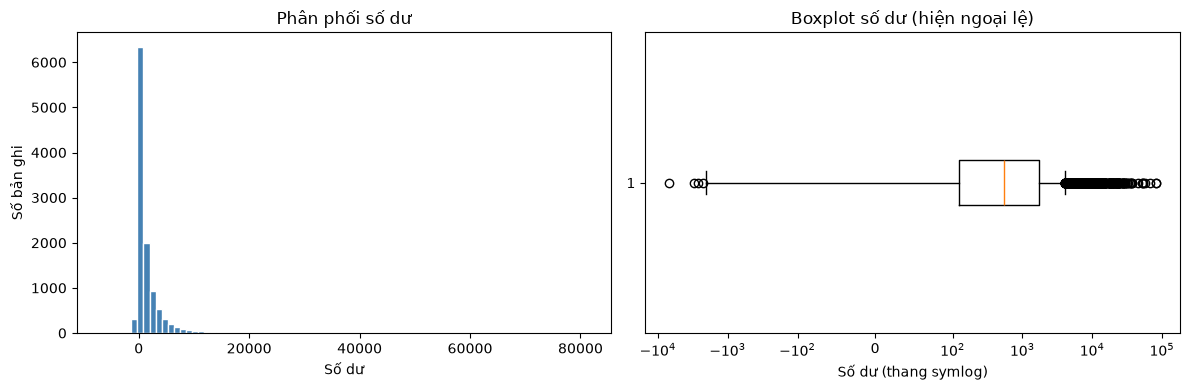

Số dư: trung bình 1,529, trung vị 550; IQR đánh dấu 1,055 giá trị.


In [4]:
# Quan sát phân phối và ngoại lệ của số dư
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(clean['balance'], bins=80, color='steelblue', edgecolor='white')
axes[0].set(title='Phân phối số dư', xlabel='Số dư', ylabel='Số bản ghi')
axes[1].boxplot(clean['balance'], vert=False, showfliers=True)
axes[1].set_xscale('symlog', linthresh=100)
axes[1].set(title='Boxplot số dư (hiện ngoại lệ)', xlabel='Số dư (thang symlog)')
plt.tight_layout()
plt.show()
print(f"Số dư: trung bình {clean['balance'].mean():,.0f}, trung vị {clean['balance'].median():,.0f}; IQR đánh dấu {outliers['balance']:,} giá trị.")

Nhận xét: Histogram cho thấy số dư tập trung ở vùng giá trị thấp và có đuôi kéo dài về bên phải. Trung bình khoảng 1.529 cao hơn trung vị 550; số dư lớn nhất là 81.204. Có 1.055 giá trị nằm ngoài ngưỡng IQR, chiếm khoảng 9,45% số dòng.

Boxplot dùng thang `symlog` để hiển thị cả số âm và số dương lớn. Khoảng cách trên trục này không đều như thang tuyến tính. Các điểm ngoài râu là ngoại lệ theo IQR; cần kiểm tra thêm trước khi quyết định loại khỏi dữ liệu.

Kết quả kiểm tra: Dữ liệu có 11.162 dòng và 17 cột, không có giá trị null hoặc dòng trùng hoàn toàn. Nhãn `unknown` xuất hiện ở `job` (70 dòng), `education` (497 dòng), `contact` (2.346 dòng, 21,02%) và `poutcome` (8.326 dòng, 74,59%).

Trong 8.326 dòng có `poutcome = unknown`, có 8.324 dòng có `pdays = -1`, tức chưa được liên hệ trong chiến dịch trước. Hai dòng còn lại có thông tin số ngày kể từ lần liên hệ trước nhưng chưa xác định kết quả. Sau bước làm sạch, số dòng vẫn là 11.162; các ngoại lệ IQR được giữ lại.

## 3. Phân tích và trực quan hóa

Tỷ lệ đăng ký của mỗi nhóm được tính bằng số dòng `deposit = yes` chia cho tổng số dòng của nhóm đó.

Bài dùng kiểm định chi-square với mức ý nghĩa 5% cho hai câu hỏi:

- Kết quả đăng ký có liên hệ với nhóm tuổi không? H₀: hai biến độc lập. H₁: hai biến có mối liên hệ.
- Kết quả đăng ký có liên hệ với tình trạng vay nhà không? H₀: hai biến độc lập. H₁: hai biến có mối liên hệ.

Nếu p-value nhỏ hơn 0,05 thì bác bỏ H₀. Tần số kỳ vọng được kiểm tra ở mỗi bảng để xem có đáp ứng điều kiện từ 5 trở lên hay không. Dữ liệu không có mã khách hàng nên chưa xác minh được tính độc lập giữa các dòng. Nếu một khách hàng xuất hiện nhiều lần, kết quả kiểm định có thể bị ảnh hưởng. Các kiểm định này đánh giá mối liên hệ, chưa xác định được quan hệ nhân quả.

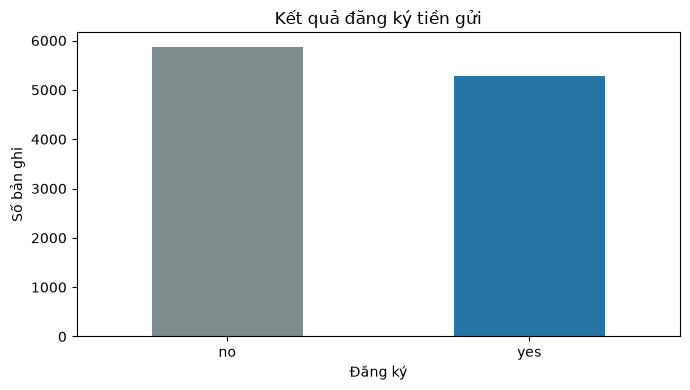

deposit
no     5873
yes    5289
Name: count, dtype: int64
Tỷ lệ đăng ký (%): 47.4


In [5]:
# Phân bố kết quả đăng ký
counts = clean['deposit'].value_counts().reindex(['no', 'yes'])
ax = counts.plot.bar(color=['#7f8c8d', '#2874a6'], rot=0, figsize=(7, 4))
ax.set(title='Kết quả đăng ký tiền gửi', xlabel='Đăng ký', ylabel='Số bản ghi')
plt.tight_layout()
plt.show()
print(counts)
print("Tỷ lệ đăng ký (%):", round(counts["yes"] / len(clean) * 100, 1))

Nhận xét: Có 5.289 bản ghi đăng ký tiền gửi (47,4%) và 5.873 bản ghi không đăng ký (52,6%). Nhóm không đăng ký nhiều hơn 584 bản ghi. Tỷ lệ 47,4% được dùng làm mốc so sánh các nhóm trong bài; đây là tỷ lệ của mẫu đang phân tích, chưa thể xem là tỷ lệ chung của toàn bộ khách hàng hay của một chiến dịch mới.

,Số bản ghi,Số đăng ký,Tỷ lệ đăng ký
nhom_tuoi,,,
≤30,2007,1145,0.570503
31–40,4188,1812,0.432665
41–50,2496,1019,0.408253
51–60,1860,811,0.436022
>60,611,502,0.821604


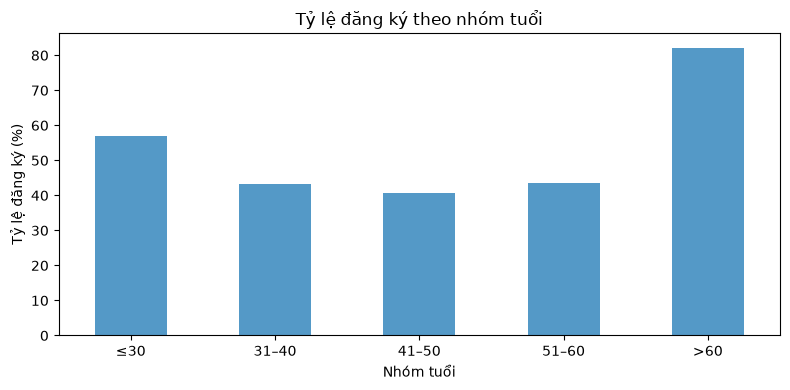

Kiểm định chi-square: χ²=453.82, bậc tự do=4, p=6.48e-97; kỳ vọng nhỏ nhất=289.5.
Bác bỏ H0 ở mức ý nghĩa 5%.


In [6]:
# So sánh tỷ lệ đăng ký theo nhóm tuổi
age_stats = clean.groupby('nhom_tuoi', observed=True)['deposit_yes'].agg(['size', 'sum', 'mean'])
display(age_stats.rename(columns={'size': 'Số bản ghi', 'sum': 'Số đăng ký', 'mean': 'Tỷ lệ đăng ký'}))
ax = (age_stats['mean'] * 100).plot.bar(color='#5499c7', rot=0, figsize=(8, 4))
ax.set(title='Tỷ lệ đăng ký theo nhóm tuổi', xlabel='Nhóm tuổi', ylabel='Tỷ lệ đăng ký (%)')
plt.tight_layout()
plt.show()
table_age = pd.crosstab(clean['nhom_tuoi'], clean['deposit'])
chi, p_age, dof, expected = chi2_contingency(table_age)
print(f'Kiểm định chi-square: χ²={chi:.2f}, bậc tự do={dof}, p={p_age:.3g}; kỳ vọng nhỏ nhất={expected.min():.1f}.')
if p_age < 0.05:
    print('Bác bỏ H0 ở mức ý nghĩa 5%.')
else:
    print('Chưa đủ bằng chứng để bác bỏ H0 ở mức ý nghĩa 5%.')

Nhận xét: Nhóm trên 60 tuổi có tỷ lệ đăng ký cao nhất, đạt 82,2% (502/611 bản ghi). Nhóm từ 41 đến 50 tuổi thấp nhất, đạt 40,8% (1.019/2.496 bản ghi). Nhóm từ 31 đến 40 tuổi có quy mô lớn nhất với 4.188 bản ghi và tỷ lệ đăng ký 43,3%. Vì quy mô các nhóm khác nhau, cần đọc tỷ lệ cùng với số bản ghi.

Kiểm định cho p-value khoảng 6,48 × 10⁻⁹⁷, nhỏ hơn 0,05 nên bác bỏ H₀. Có bằng chứng thống kê về mối liên hệ giữa nhóm tuổi và kết quả đăng ký trong mẫu. Tần số kỳ vọng nhỏ nhất là 289,5, đáp ứng điều kiện kiểm định. Kết quả chưa cho biết tuổi là nguyên nhân của khác biệt này; tính độc lập của các dòng cũng chưa được xác minh.

,Số bản ghi,Số đăng ký,Tỷ lệ đăng ký
housing,,,
no,5881,3354,0.570311
yes,5281,1935,0.366408


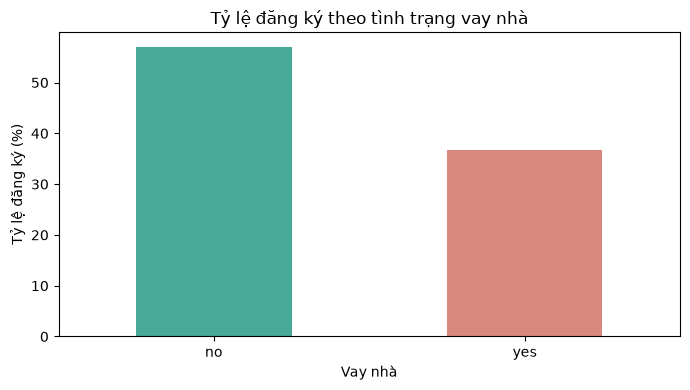

Kiểm định chi-square: χ²=463.19, bậc tự do=1, p=9.72e-103; kỳ vọng nhỏ nhất=2502.3.
Bác bỏ H0 ở mức ý nghĩa 5%.


In [7]:
# So sánh theo tình trạng vay nhà
housing = clean.groupby('housing')['deposit_yes'].agg(['size', 'sum', 'mean'])
display(housing.rename(columns={'size': 'Số bản ghi', 'sum': 'Số đăng ký', 'mean': 'Tỷ lệ đăng ký'}))
ax = (housing['mean'] * 100).plot.bar(color=['#48a999', '#d98880'], rot=0, figsize=(7, 4))
ax.set(title='Tỷ lệ đăng ký theo tình trạng vay nhà', xlabel='Vay nhà', ylabel='Tỷ lệ đăng ký (%)')
plt.tight_layout()
plt.show()
chi, p_housing, dof, expected = chi2_contingency(pd.crosstab(clean['housing'], clean['deposit']))
print(f'Kiểm định chi-square: χ²={chi:.2f}, bậc tự do={dof}, p={p_housing:.3g}; kỳ vọng nhỏ nhất={expected.min():.1f}.')
if p_housing < 0.05:
    print('Bác bỏ H0 ở mức ý nghĩa 5%.')
else:
    print('Chưa đủ bằng chứng để bác bỏ H0 ở mức ý nghĩa 5%.')

Nhận xét: Nhóm không vay nhà có tỷ lệ đăng ký 57,0% (3.354/5.881 bản ghi), còn nhóm có vay nhà đạt 36,6% (1.935/5.281 bản ghi). Chênh lệch là 20,4 điểm phần trăm.

P-value khoảng 9,72 × 10⁻¹⁰³, nhỏ hơn 0,05 nên bác bỏ H₀. Có bằng chứng thống kê về mối liên hệ giữa tình trạng vay nhà và kết quả đăng ký trong mẫu. Tần số kỳ vọng nhỏ nhất là 2.502,3, đáp ứng điều kiện kiểm định. Chưa thể kết luận vay nhà làm giảm khả năng đăng ký, vì bài chưa kiểm soát các đặc điểm khác của khách hàng và chưa xác minh tính độc lập giữa các dòng.

,Số bản ghi,Số đăng ký,Tỷ lệ đăng ký
poutcome,,,
success,1071,978,0.913165
other,537,307,0.571695
failure,1228,618,0.503257
unknown,8326,3386,0.406678


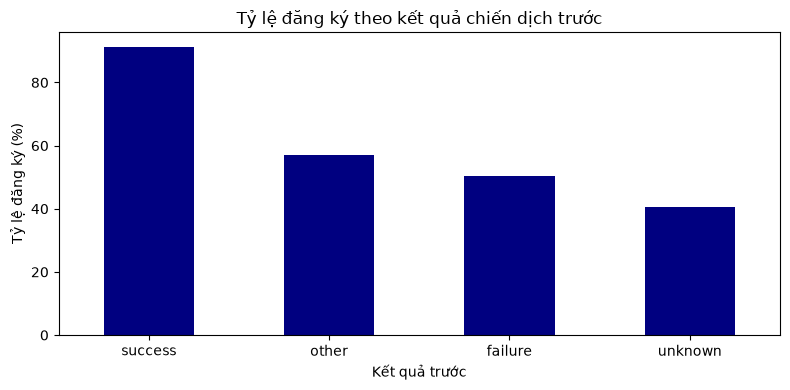

Trong nhóm unknown: 8,324 chưa liên hệ trước; 2 có ngày liên hệ nhưng chưa xác định kết quả trước.


In [8]:
# Phân tích kết quả chiến dịch trước
previous = clean.groupby('poutcome')['deposit_yes'].agg(['size', 'sum', 'mean']).sort_values('mean', ascending=False)
display(previous.rename(columns={'size': 'Số bản ghi', 'sum': 'Số đăng ký', 'mean': 'Tỷ lệ đăng ký'}))
ax = (previous['mean'] * 100).plot.bar(color='navy', rot=0, figsize=(8, 4))
ax.set(title='Tỷ lệ đăng ký theo kết quả chiến dịch trước', xlabel='Kết quả trước', ylabel='Tỷ lệ đăng ký (%)')
plt.tight_layout()
plt.show()
unknown_history = clean[clean['poutcome'] == 'unknown']['pdays']
print(f"Trong nhóm unknown: {(unknown_history == -1).sum():,} chưa liên hệ trước; {(unknown_history != -1).sum():,} có ngày liên hệ nhưng chưa xác định kết quả trước.")

Nhận xét: Nhóm có kết quả chiến dịch trước là `success` có tỷ lệ đăng ký cao nhất, đạt 91,3% (978/1.071 bản ghi). Các nhóm `other`, `failure` và `unknown` lần lượt đạt khoảng 57,2%, 50,3% và 40,7%.

Nhóm `unknown` chiếm 74,6% mẫu. Trong 8.326 dòng thuộc nhóm này, 8.324 dòng chưa được liên hệ trong chiến dịch trước (`pdays = -1`); hai dòng còn lại có thông tin số ngày kể từ lần liên hệ trước nhưng kết quả chưa xác định. Vì vậy, phần lớn nhóm `unknown` chưa có lịch sử liên hệ để so sánh với nhóm `success`. Bảng cho thấy khác biệt giữa các nhóm, chưa chứng minh việc liên hệ lại làm tăng tỷ lệ đăng ký.

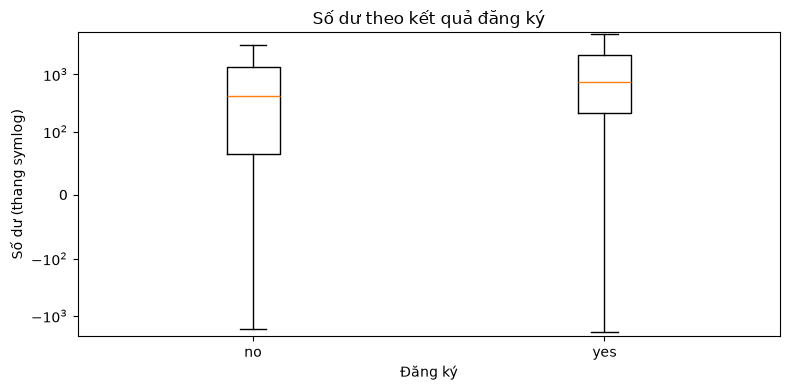

Trung vị số dư theo kết quả đăng ký:
deposit
no     414.0
yes    733.0
Name: balance, dtype: float64


In [9]:
# Phân phối số dư theo kết quả, dùng thang đối xứng để giữ cả số âm
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([clean.loc[clean['deposit'] == v, 'balance'] for v in ['no', 'yes']], showfliers=False)
ax.set_xticks([1, 2], ['no', 'yes'])
ax.set_yscale('symlog', linthresh=100)
ax.set(title='Số dư theo kết quả đăng ký', xlabel='Đăng ký', ylabel='Số dư (thang symlog)')
plt.tight_layout()
plt.show()
med = clean.groupby('deposit')['balance'].median()
print("Trung vị số dư theo kết quả đăng ký:")
print(med)

Nhận xét: Trung vị số dư của nhóm đăng ký là 733, cao hơn nhóm không đăng ký là 414, chênh lệch 319. Hai boxplot vẫn có phần chồng lấn, nên riêng số dư chưa đủ để phân biệt khách hàng đăng ký và không đăng ký.

Biểu đồ dùng thang `symlog` để giữ cả số dư âm và số dư lớn. Các điểm ngoài râu được ẩn cho dễ quan sát nhưng vẫn nằm trong dữ liệu phân tích. Chênh lệch trung vị là kết quả mô tả, chưa chứng minh số dư cao làm tăng khả năng đăng ký.

## 4. Tác động, khuyến nghị và giới hạn

### Các phát hiện chính

- Nhóm trên 60 tuổi có tỷ lệ đăng ký 82,2%, cao nhất trong các nhóm tuổi, nhưng chỉ có 611 bản ghi. Nhóm từ 31 đến 40 tuổi có nhiều bản ghi nhất, với tỷ lệ đăng ký 43,3%.
- Nhóm không vay nhà có tỷ lệ đăng ký 57,0%, cao hơn nhóm có vay nhà 20,4 điểm phần trăm.
- Nhóm có kết quả chiến dịch trước là `success` đạt tỷ lệ đăng ký 91,3%. Tuy nhiên, 74,6% mẫu thuộc nhóm `unknown`, phần lớn chưa được liên hệ trong chiến dịch trước.

### Đề xuất

Có thể thử thông điệp khác nhau theo nhóm tuổi và tình trạng vay nhà. Với mỗi nhóm, phân bổ ngẫu nhiên khách hàng vào nhóm dùng thông điệp mới và nhóm dùng thông điệp hiện tại, sau đó so sánh tỷ lệ đăng ký và chi phí trên mỗi lượt đăng ký. Tuổi hoặc tình trạng vay nhà không nên là căn cứ duy nhất để loại khách hàng.

Với khách hàng từng có kết quả chiến dịch thành công, có thể thử liên hệ lại trên một phần mẫu và so sánh với nhóm đối chứng được chọn ngẫu nhiên trong cùng nhóm khách hàng này. Hiệu quả thực tế cần được đo trước khi mở rộng. Cần kiểm tra thêm hai dòng có thông tin số ngày liên hệ trước nhưng chưa xác định kết quả.

### Giới hạn và hướng mở rộng

Dữ liệu quan sát chưa cho phép kết luận quan hệ nhân quả. Mẫu có thể chưa đại diện cho toàn bộ khách hàng, còn nhãn `unknown` và chưa xác minh được khách hàng lặp lại. Bài cũng chưa kiểm soát các yếu tố khác khi so sánh các nhóm.

Do thiếu thông tin chi phí, lợi nhuận và thứ tự thời gian đầy đủ, chưa đánh giá được hiệu quả kinh tế hoặc khả năng áp dụng cho chiến dịch mới. Có thể bổ sung mã khách hàng ẩn danh, thời điểm liên hệ, chi phí và dữ liệu chiến dịch mới để kiểm tra tính đại diện và đánh giá ở giai đoạn sau.

Nếu phát triển mô hình dự báo trước cuộc gọi, cần loại `duration`, chia tập dữ liệu trước khi thực hiện các bước điền thiếu, mã hóa và đánh giá trên tập kiểm tra độc lập.